IMPORT THE LIBRARIES

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

IMPORT THE DATASET

In [18]:
dataset = pd.read_csv(
    "vehicle.data",
    header=None,
    names=[
        "buying",
        "maint",
        "doors",
        "persons",
        "lug_boot",
        "safety",
        "class"
    ]
)
dataset.head()

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [6]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1727 entries, 0 to 1726
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   vhigh    1727 non-null   str  
 1   vhigh.1  1727 non-null   str  
 2   2        1727 non-null   str  
 3   2.1      1727 non-null   str  
 4   small    1727 non-null   str  
 5   low      1727 non-null   str  
 6   unacc    1727 non-null   str  
dtypes: str(7)
memory usage: 94.6 KB


In [25]:
print(dataset.shape)

(1728, 7)


CHECK FOR MISSING VALUES

In [16]:
dataset.isnull().sum()

vhigh      0
vhigh.1    0
2          0
2.1        0
small      0
low        0
unacc      0
dtype: int64

In [24]:
print(dataset['class'].value_counts())

class
2    1210
0     384
1      69
3      65
Name: count, dtype: int64


ENCODE:

X AND Y DATA:

In [26]:
X = dataset.iloc[:, :-1]
Y = dataset.iloc[:, -1]

ENCODING THE CATEGORICAL DATA OF OUTPUT COLUMN TRANSFORMER

In [31]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
Y=np.array(le.fit_transform(Y))
Y

array([2, 2, 2, ..., 2, 1, 3], shape=(1728,))

ENCODING THE CATEGORICAL DATA OF FEATURE MATRIX

In [28]:
from sklearn.preprocessing import OrdinalEncoder
oe=OrdinalEncoder()
X=oe.fit_transform(X)
X

array([[3., 3., 0., 0., 2., 1.],
       [3., 3., 0., 0., 2., 2.],
       [3., 3., 0., 0., 2., 0.],
       ...,
       [1., 1., 3., 2., 0., 1.],
       [1., 1., 3., 2., 0., 2.],
       [1., 1., 3., 2., 0., 0.]], shape=(1728, 6))

SPLITTING THE DATASET INTO TRAINING AND TESTING SET

In [32]:
from sklearn.model_selection import train_test_split
Xtrain,Xtest,Ytrain,Ytest=train_test_split(X,Y,test_size=0.2,random_state=42)

FEATURE SCALING

In [35]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
Xtrain = sc.fit_transform(Xtrain)
Xtest = sc.transform(Xtest)

TRAIN THE KNN

In [37]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Xtrain, Ytrain)


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[0,1,2,3]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


TESTING:

In [38]:
Ypred = knn.predict(Xtest)

EVALUATE

ACCURACY

In [40]:
from sklearn.metrics import accuracy_score, classification_report
print("Accuracy =",
      accuracy_score(Ytest, Ypred))

print(classification_report(
      Ytest,
      Ypred))

Accuracy = 0.9421965317919075
              precision    recall  f1-score   support

           0       0.87      0.89      0.88        83
           1       1.00      0.64      0.78        11
           2       0.97      1.00      0.98       235
           3       0.92      0.65      0.76        17

    accuracy                           0.94       346
   macro avg       0.94      0.79      0.85       346
weighted avg       0.94      0.94      0.94       346



CONFUSION MATRIX

In [41]:
from sklearn.metrics import confusion_matrix
Ypred = knn.predict(Xtest)
cm = confusion_matrix(Ytest, Ypred)
print(cm)


[[ 74   0   8   1]
 [  4   7   0   0]
 [  1   0 234   0]
 [  6   0   0  11]]


CLASSIFICATION REPORT

In [42]:
print("Classification Report:")
print(classification_report(
    Ytest,
    Ypred
))

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.89      0.88        83
           1       1.00      0.64      0.78        11
           2       0.97      1.00      0.98       235
           3       0.92      0.65      0.76        17

    accuracy                           0.94       346
   macro avg       0.94      0.79      0.85       346
weighted avg       0.94      0.94      0.94       346



PLOTTING AND FINDING BEST K:

In [43]:
accuracy = []

for k in range(1,21):

    model = KNeighborsClassifier(
        n_neighbors=k
    )

    model.fit(Xtrain, Ytrain)

    pred = model.predict(Xtest)

    accuracy.append(
        accuracy_score(
            Ytest,
            pred
        )
    )

PLOT

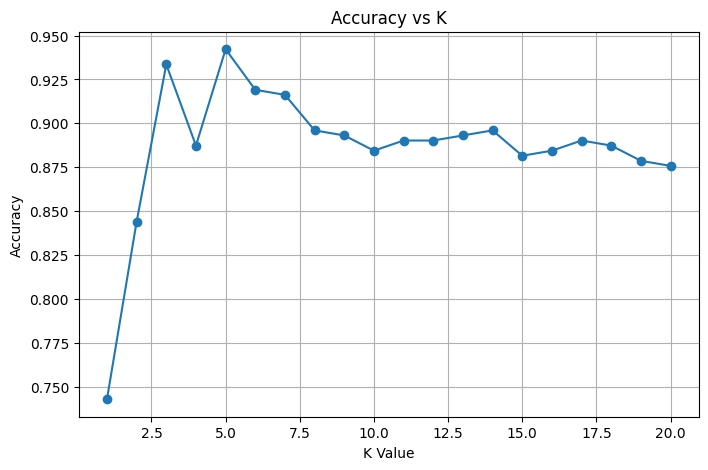

In [44]:
plt.figure(figsize=(8,5))
plt.plot(
    range(1,21),
    accuracy,
    marker='o'
)
plt.xlabel("K Value")
plt.ylabel("Accuracy")
plt.title("Accuracy vs K")

plt.grid(True)

plt.show()

ACCURACY:

In [45]:
for k,acc in zip(range(1,21),accuracy):
    print(
        f"K={k}  Accuracy={acc:.4f}"
    )

K=1  Accuracy=0.7428
K=2  Accuracy=0.8439
K=3  Accuracy=0.9335
K=4  Accuracy=0.8873
K=5  Accuracy=0.9422
K=6  Accuracy=0.9191
K=7  Accuracy=0.9162
K=8  Accuracy=0.8960
K=9  Accuracy=0.8931
K=10  Accuracy=0.8844
K=11  Accuracy=0.8902
K=12  Accuracy=0.8902
K=13  Accuracy=0.8931
K=14  Accuracy=0.8960
K=15  Accuracy=0.8815
K=16  Accuracy=0.8844
K=17  Accuracy=0.8902
K=18  Accuracy=0.8873
K=19  Accuracy=0.8786
K=20  Accuracy=0.8757


BEST K:

In [46]:
best_k = accuracy.index(max(accuracy)) + 1
print("Best K =", best_k)
print("Best Accuracy =", max(accuracy))

Best K = 5
Best Accuracy = 0.9421965317919075


CONCLUSION

In [53]:
print(f"The KNN Classifier was successfully trained on the Vehicle Dataset.")

The KNN Classifier was successfully trained on the Vehicle Dataset.


In [ ]:
THE KNN CLASSIFIER WAS SUCCESSFULLY TRAINED ON THE VEHICLE DATASET.THE HIGHEST ACCURACY OBTAINED WAS 94.21% USING K=5.